<div style="text-align:center; border-radius:20px; padding:25px; color:white; margin:0; font-family:sans-serif; background:#1b002a; box-shadow:0px 6px 18px rgba(0,0,0,0.35); margin-bottom:1em;">
          <div style="font-size:200%; color:#FEE100; font-weight:700;">
            e-commerce-customer-behavior-and-sales-20202026-ETL,EDA,Visualize,Model
          </div>
        </div>
        

![Dataset Image](https://holosen.net/api/file/86912b04-3247-4ac5-9844-c89c2dc0f796)


In [1]:
import os
main_csv_local_path = 'customers.csv'
DATA_DIR = ''
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        if filename == main_csv_local_path:
            DATA_DIR = os.path.join(dirname, filename)
            print(DATA_DIR)


/kaggle/input/datasets/meruvakodandasuraj/e-commerce-customer-behavior-and-sales-20202026/customers.csv


--- Dataset Shape ---
(8000, 20)

--- Dataset Info ---
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8000 entries, 0 to 7999
Data columns (total 20 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   customer_id               8000 non-null   object 
 1   country                   8000 non-null   object 
 2   age                       8000 non-null   int64  
 3   gender                    8000 non-null   object 
 4   membership_tier           8000 non-null   object 
 5   registration_date         8000 non-null   object 
 6   total_orders              8000 non-null   int64  
 7   total_spend_usd           8000 non-null   float64
 8   avg_order_value_usd       8000 non-null   float64
 9   days_since_last_purchase  8000 non-null   int64  
 10  preferred_category        8000 non-null   object 
 11  preferred_device          8000 non-null   object 
 12  preferred_payment_method  8000 non-null   object 
 13  acquisit

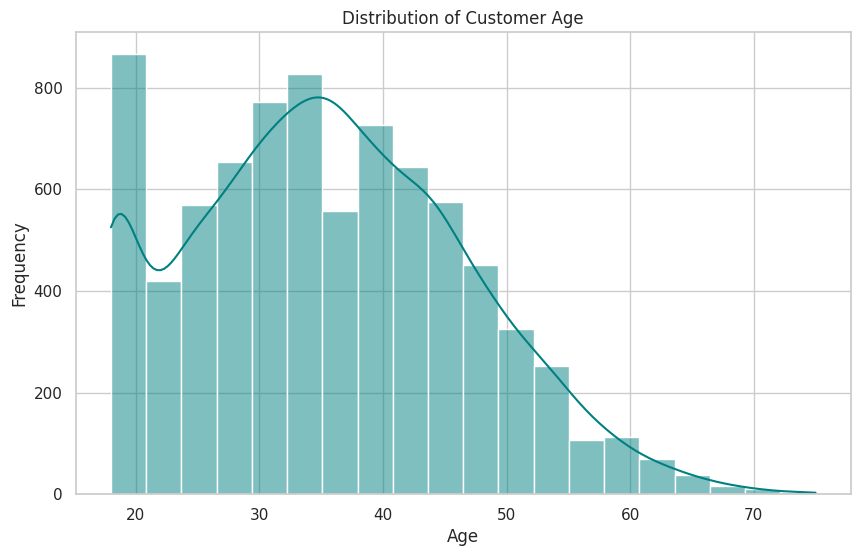

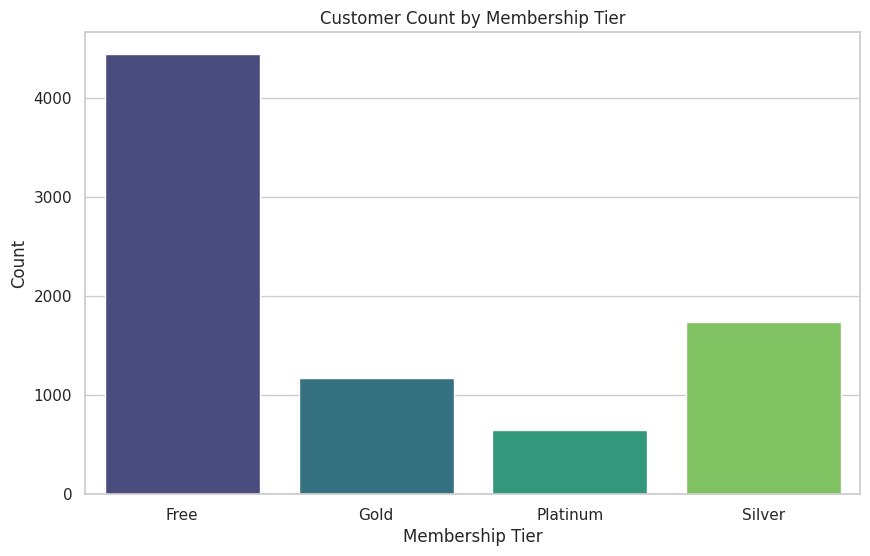

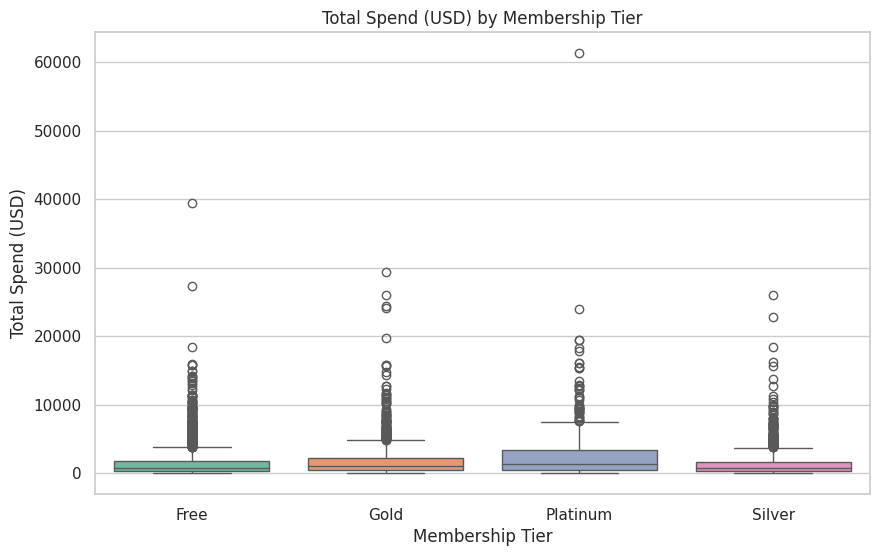

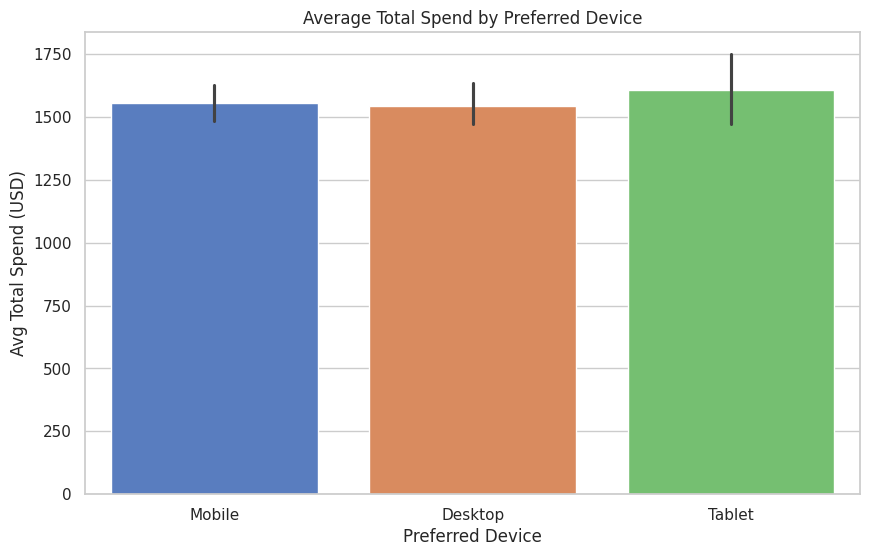

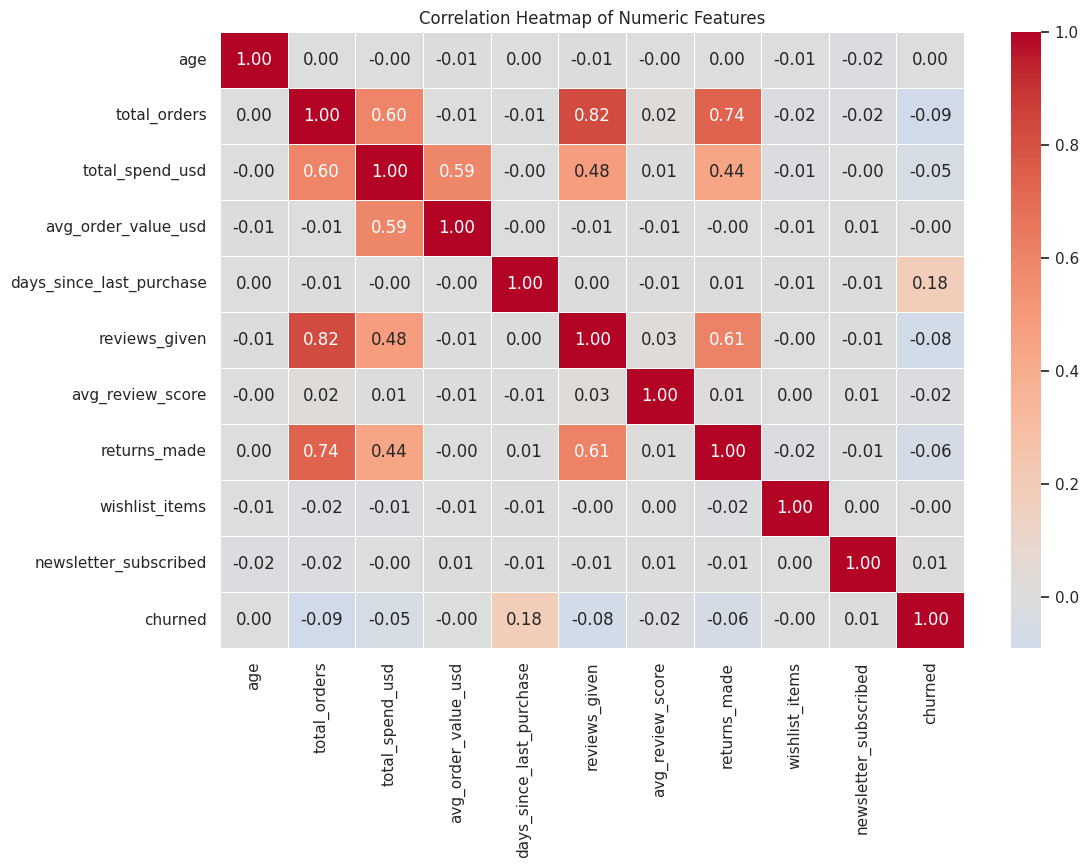


--- Dataset Sample ---
     customer_id        country  age  gender membership_tier  \
3003      C03004          Japan   33  Female            Free   
4176      C04177  United States   25  Female            Free   
324       C00325  United States   44    Male          Silver   
4508      C04509         Canada   37    Male            Free   
7142      C07143         Mexico   28    Male            Free   
229       C00230          Italy   58  Female          Silver   
7838      C07839         Brazil   26    Male            Free   
2298      C02299  United States   26    Male            Free   
5724      C05725         Canada   29  Female          Silver   
1214      C01215  United States   38    Male            Free   

     registration_date  total_orders  total_spend_usd  avg_order_value_usd  \
3003        2025-01-30            12          1193.93                94.78   
4176        2022-06-19            14           376.69                29.15   
324         2024-05-21            18 

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

# Set standard plotting style for Kaggle environment
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 6)

# 1. LOAD DATA
# DATA_DIR is assumed to be predefined in the environment pointing to the CSV file path.
df = pd.read_csv(DATA_DIR)

# 2. BASIC INSPECTION
print("--- Dataset Shape ---")
print(df.shape)

print("\n--- Dataset Info ---")
df.info()

print("\n--- First 5 Rows ---")
print(df.head())

# 3. ETL (Safe Cleaning & Type Casting)
# Safe date conversion
df['registration_date'] = pd.to_datetime(df['registration_date'], errors='coerce')

# Handling missing values (Safe defaults)
# Check for nulls
null_counts = df.isnull().sum()
if null_counts.any():
    print("\n--- Null Values Detected ---")
    print(null_counts[null_counts > 0])
    # Fill numeric columns with median
    numeric_cols = df.select_dtypes(include=[np.number]).columns
    df[numeric_cols] = df[numeric_cols].fillna(df[numeric_cols].median())
    # Fill categorical columns with mode
    categorical_cols = df.select_dtypes(include=['object']).columns
    for col in categorical_cols:
        df[col] = df[col].fillna(df[col].mode()[0])
else:
    print("\n--- No Null Values Found ---")

# 4. EDA (Summary Statistics)
print("\n--- Numerical Summary Statistics ---")
print(df.describe())

# 5. VISUALIZATION
# Distribution of Age
plt.figure()
sns.histplot(data=df, x='age', kde=True, color='teal', bins=20)
plt.title('Distribution of Customer Age')
plt.xlabel('Age')
plt.ylabel('Frequency')
plt.show()

# Membership Tier Distribution
plt.figure()
sns.countplot(data=df, x='membership_tier', hue='membership_tier', palette='viridis', legend=False)
plt.title('Customer Count by Membership Tier')
plt.xlabel('Membership Tier')
plt.ylabel('Count')
plt.show()

# Total Spend vs Membership Tier (Boxplot)
plt.figure()
sns.boxplot(data=df, x='membership_tier', y='total_spend_usd', hue='membership_tier', palette='Set2', legend=False)
plt.title('Total Spend (USD) by Membership Tier')
plt.xlabel('Membership Tier')
plt.ylabel('Total Spend (USD)')
plt.show()

# Average Spend by Preferred Device (Barplot)
plt.figure()
sns.barplot(data=df, x='preferred_device', y='total_spend_usd', hue='preferred_device', palette='muted', legend=False)
plt.title('Average Total Spend by Preferred Device')
plt.xlabel('Preferred Device')
plt.ylabel('Avg Total Spend (USD)')
plt.show()

# Correlation Heatmap for Numeric Columns
plt.figure(figsize=(12, 8))
numeric_data = df.select_dtypes(include=[np.number])
correlation_matrix = numeric_data.corr()
sns.heatmap(correlation_matrix, annot=True, fmt=".2f", cmap='coolwarm', center=0, linewidths=0.5)
plt.title('Correlation Heatmap of Numeric Features')
plt.show()

# 6. DATASET SAMPLE DISPLAY
print("\n--- Dataset Sample ---")
print(df.sample(min(len(df), 10)))
